In [ ]:
import scipy.ndimage as ndi
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import math
import nibabel as nib
import skimage.transform
import pathlib
import pandas as pd
import tensorflow.keras.backend as K
from scipy import ndimage
import skimage.feature, skimage.measure, skimage.morphology, skimage.segmentation
import glob
from sklearn.model_selection import train_test_split
import tensorflow.keras.backend as K
import keras
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Activation, Flatten, BatchNormalization, \
    Conv2D, MaxPooling2D, ZeroPadding2D, Input, Embedding, \
    Lambda, UpSampling2D, Cropping2D, Conv2DTranspose, concatenate
import tensorflow as tf
from keras.optimizers import SGD, Adam
from keras.callbacks import ModelCheckpoint, LearningRateScheduler, ReduceLROnPlateau, CSVLogger
from keras import backend as K
from keras import optimizers
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import array_to_img
from skimage.transform import resize
from tensorflow.keras import models, layers, regularizers
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
from skimage.transform import resize
from tensorflow.keras.utils import array_to_img, Sequence
from skimage.transform import resize

2024-11-04 12:12:38.257622: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-04 12:12:38.257836: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-04 12:12:38.428678: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
#### Load train data of 3d mask with npy
#################################################

path = "/kaggle/input/newnodules/new_ct (S123)/"
mask_path = "/kaggle/input/newnodules/new_mask (S123)/"

CT_list = glob.glob(path + "*.npy")
mask_list = glob.glob(mask_path + "*.npy")

Patient_ID = []
x_train = []
y_train = []



for i in range(len(CT_list)):
  print(i)
  Patient_ID.append(CT_list[i].split("/")[-1][:-4])

  temp = np.load(CT_list[i])
  mask_temp = np.load(mask_path + Patient_ID[i] + ".npy")

  x = np.zeros((np.shape(temp)[0], 256, 256))
  y = np.zeros((np.shape(temp)[0], 256, 256))

  for j in range(np.shape(temp)[0]):



    x[j, :, :] = (resize(temp[j, :, :], (256, 256)))
    y[j, :, :] = (resize(mask_temp[j, :, :], (256, 256)))



  x_train.append(x)
  y_train.append(y)



x_train = np.concatenate(x_train, axis=0)
y_train = np.concatenate(y_train, axis=0)

# Y_train = np.multiply(Y_train,1)
del temp, mask_temp, x, y

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181


In [4]:
#### Shuffle data

indices = np.arange(x_train.shape[0])
np.random.shuffle(indices)

x_train = x_train[indices, :, :]
y_train = y_train[indices, :, :]

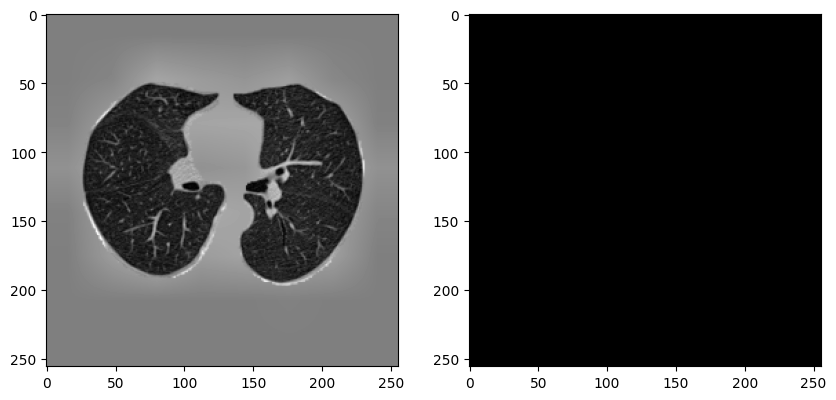

In [5]:
index = 950
plt.figure(figsize=[10, 10])
plt.subplot(121)
plt.imshow(x_train[index, :, :], cmap="gray")
plt.subplot(122)
plt.imshow(y_train[index, :, :], cmap="gray")
plt.show()

In [ ]:
###### Normalize
epsilon = np.finfo(x_train.dtype).eps
for i in range(len(x_train)):
  temp = x_train[i, :, :]
 

  x_train[i, :, :] = (temp - np.min(temp))/ (np.max(temp)-np.min(temp)+epsilon)




In [7]:
np.min(x_train)

0.0

In [ ]:

def dice_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + 1) / (K.sum(y_true_f) + K.sum(y_pred_f) + 1)

def dice_coef_loss(y_true, y_pred):
    return 1-dice_coef(y_true, y_pred)



# Dice Coefficient Metric
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# Sensitivity (Recall) Metric
def sensitivity_metric(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    true_positives = K.sum(y_true_f * y_pred_f)
    possible_positives = K.sum(y_true_f)
    return true_positives / (possible_positives + K.epsilon())

# Precision Metric
def precision_metric(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    true_positives = K.sum(y_true_f * y_pred_f)
    predicted_positives = K.sum(y_pred_f)
    return true_positives / (predicted_positives + K.epsilon())


def dice_coef_loss(y_true, y_pred, smooth=1e-6):
    # Flatten the predictions and labels
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    
    # Calculate the Dice coefficient
    intersection = K.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)
    
    return dice


In [9]:
X_train , X_test, Y_train, Y_test = train_test_split(x_train, y_train, test_size=0.05, random_state=32)
del x_train, y_train

In [10]:
X_train = np.reshape(X_train, (len(X_train), 256, 256, 1))
Y_train = np.reshape(Y_train, (len(Y_train), 256, 256, 1))
X_test = np.reshape(X_test, (len(X_test), 256, 256, 1))
Y_test = np.reshape(Y_test, (len(Y_test), 256, 256, 1))

In [11]:
#convolutional block
def conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(x)
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
    if dropout > 0:
        conv = layers.Dropout(dropout)(conv)
    conv = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding="same")(conv)
    if batchnorm is True:
        conv = layers.BatchNormalization(axis=3)(conv)
    conv = layers.Activation("relu")(conv)
    return conv


#residual convolutional block
def res_conv_block(x, kernelsize, filters, dropout, batchnorm=False):
    conv1 = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm is True:
        conv1 = layers.BatchNormalization(axis=3)(conv1)
    conv1 = layers.Activation('relu')(conv1)
    conv2 = layers.Conv2D(filters, (kernelsize, kernelsize), kernel_initializer='he_normal', padding='same')(conv1)
    if batchnorm is True:
        conv2 = layers.BatchNormalization(axis=3)(conv2)
        conv2 = layers.Activation("relu")(conv2)
    if dropout > 0:
        conv2 = layers.Dropout(dropout)(conv2)

    #skip connection
    shortcut = layers.Conv2D(filters, kernel_size=(1, 1), kernel_initializer='he_normal', padding='same')(x)
    if batchnorm is True:
        shortcut = layers.BatchNormalization(axis=3)(shortcut)
    shortcut = layers.Activation("relu")(shortcut)
    respath = layers.add([shortcut, conv2])
    return respath


#gating signal for attention unit
def gatingsignal(input, out_size, batchnorm=False):
    x = layers.Conv2D(out_size, (1, 1), padding='same')(input)
    if batchnorm:
        x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

#attention unit/block based on soft attention
def attention_block(x, gating, inter_shape):
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)
    theta_x = layers.Conv2D(inter_shape, (2, 2), strides=(2, 2), kernel_initializer='he_normal', padding='same')(x)
    shape_theta_x = K.int_shape(theta_x)
    phi_g = layers.Conv2D(inter_shape, (1, 1), kernel_initializer='he_normal', padding='same')(gating)
    upsample_g = layers.Conv2DTranspose(inter_shape, (3, 3), strides=(shape_theta_x[1] // shape_g[1], shape_theta_x[2] // shape_g[2]), kernel_initializer='he_normal', padding='same')(phi_g)
    concat_xg = layers.add([upsample_g, theta_x])
    act_xg = layers.Activation('relu')(concat_xg)
    psi = layers.Conv2D(1, (1, 1), kernel_initializer='he_normal', padding='same')(act_xg)
    sigmoid_xg = layers.Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)
    upsample_psi = layers.UpSampling2D(size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = layers.Lambda(lambda x, repnum: K.repeat_elements(x, repnum, axis=3), arguments={'repnum': shape_x[3]})(upsample_psi)
    y = layers.multiply([upsample_psi, x])
    result = layers.Conv2D(shape_x[3], (1, 1), kernel_initializer='he_normal', padding='same')(y)
    attenblock = layers.BatchNormalization()(result)
    return attenblock


In [12]:


filters = [32, 64, 128, 256, 512]
kernelsize = 3
upsample_size = 2
dropout=0.2
batchnorm=True

inputs = keras.Input(shape = (256, 256, 1))

# Downsampling layers
dn_1 = res_conv_block(inputs, kernelsize, filters[0], dropout, batchnorm)
pool1 = layers.MaxPooling2D(pool_size=(2,2))(dn_1)

dn_2 = res_conv_block(pool1, kernelsize, filters[1], dropout, batchnorm)
pool2 = layers.MaxPooling2D(pool_size=(2,2))(dn_2)

dn_3 = res_conv_block(pool2, kernelsize, filters[2], dropout, batchnorm)
pool3 = layers.MaxPooling2D(pool_size=(2,2))(dn_3)

dn_4 = res_conv_block(pool3, kernelsize, filters[3], dropout, batchnorm)
pool4 = layers.MaxPooling2D(pool_size=(2,2))(dn_4)

dn_5 = res_conv_block(pool4, kernelsize, filters[4], dropout, batchnorm)

# Upsampling layers
gating_5 = gatingsignal(dn_5, filters[3], batchnorm)
att_5 = attention_block(dn_4, gating_5, filters[3])
up_5 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(dn_5)
up_5 = layers.concatenate([up_5, att_5], axis=3)
up_conv_5 = res_conv_block(up_5, kernelsize, filters[3], dropout, batchnorm)

gating_4 = gatingsignal(up_conv_5, filters[2], batchnorm)
att_4 = attention_block(dn_3, gating_4, filters[2])
up_4 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv_5)
up_4 = layers.concatenate([up_4, att_4], axis=3)
up_conv_4 = res_conv_block(up_4, kernelsize, filters[2], dropout, batchnorm)

gating_3 = gatingsignal(up_conv_4, filters[1], batchnorm)
att_3 = attention_block(dn_2, gating_3, filters[1])
up_3 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv_4)
up_3 = layers.concatenate([up_3, att_3], axis=3)
up_conv_3 = res_conv_block(up_3, kernelsize, filters[1], dropout, batchnorm)

gating_2 = gatingsignal(up_conv_3, filters[0], batchnorm)
att_2 = attention_block(dn_1, gating_2, filters[0])
up_2 = layers.UpSampling2D(size=(upsample_size, upsample_size), data_format="channels_last")(up_conv_3)
up_2 = layers.concatenate([up_2, att_2], axis=3)
up_conv_2 = res_conv_block(up_2, kernelsize, filters[0], dropout, batchnorm)

conv_final = layers.Conv2D(1, kernel_size=(1,1))(up_conv_2)
conv_final = layers.BatchNormalization(axis=3)(conv_final)
outputs = layers.Activation('sigmoid')(conv_final)

model = models.Model(inputs=[inputs], outputs=[outputs])
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 256,  │         64 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256, 256,  │          0 │ activation_2[0][… │
│                     │ 32)               │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ add[0][0]         │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_3[0][

 Total params: 9,786,857 (37.33 MB)

 Trainable params: 9,776,103 (37.29 MB)

 Non-trainable params: 10,754 (42.01 KB)

In [ ]:
from keras.callbacks import ModelCheckpoint

filepath = "best_model-attresunet-withS123-newloss300.h5.keras"

checkpoint = ModelCheckpoint(filepath, monitor='val_dice_coef', verbose=1, save_best_only=True, mode='max')


In [ ]:
from sklearn.utils import shuffle
opt = optimizers.Adam(learning_rate = 0.0005)

model.compile(optimizer=opt, loss=dice_coef_loss, 
              metrics=[dice_coef, sensitivity_metric, precision_metric])



In [ ]:

history = model.fit(X_train, Y_train,
                    batch_size=16,
                    shuffle = True,
                    epochs=100,
                    validation_split=0.1,
                    verbose=1,
                    callbacks=[checkpoint])

In [ ]:
pred = model.predict(X_test)

In [ ]:
pred = np.squeeze(pred, axis=-1)

In [ ]:
score = model.evaluate(X_test, Y_test, verbose = 0)

print('Test loss:', score[0])
print('Test DICE:', score[1])
print('Test sen:', score[2])
print('Test prc:', score[3])

In [ ]:
model.save_weights('/kaggle/working/WeightAttresUnet-new lossDSCBCE-3*100epoch-Lr0.0005-S123 data-1-diceloss-bs16-re-tr88va87te84s76p96.weights.h5')

In [ ]:
model.save('/kaggle/working/ModelAttresUnet-new lossDSCBCE-3*100epoch-Lr0.0005-S123 data-1-diceloss-bs16-re-tr88va87te84s76p96.weights.h5')